# B03a: Amplitude Envelope Extraction (Quick Version)

**Part 1 of 2** | ⏱️ **Duration:** ~25 minutes

> 💡 **Quick Version**: Functions are imported from `src/envelope.py` instead of being defined inline. The demonstrations are identical to the full tutorial.

## Prerequisites
- [B01: Hilbert Transform](B01_hilbert_transform.ipynb)
- [A04b: Applied Filtering](../../A_signal_fundamentals/A04b_applied_filtering.ipynb)

## Learning Objectives
By the end of this notebook, you will be able to:
- Explain what the amplitude envelope represents physically and mathematically
- Use the complete envelope extraction pipeline from `src/envelope.py`
- Analyze envelope temporal dynamics and compare smoothing methods


## Table of Contents

1. [Introduction](#section-1-introduction)
2. [What is the Amplitude Envelope?](#section-2-amplitude-envelope)
3. [Envelope vs Amplitude vs Power](#section-3-envelope-vs-power)
4. [Extracting the Envelope — Complete Pipeline](#section-4-extraction-pipeline)
5. [Temporal Dynamics of the Envelope](#section-5-temporal-dynamics)
6. [Envelope Smoothing](#section-6-smoothing)
7. [Summary](#summary)
8. [Discussion Questions](#discussion-questions)
9. [External Resources](#external-resources)


In [1]:
# =============================================================================
# Imports
# =============================================================================

# Standard library
import sys
from pathlib import Path
from typing import Tuple

# Third-party
import numpy as np
from numpy.typing import NDArray
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt, welch
from scipy.ndimage import gaussian_filter1d
from scipy.stats import pearsonr

# Local imports — functions from src/envelope.py
src_path = Path.cwd().parent.parent.parent / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from envelope import (
    extract_envelope,
    compute_envelope_psd,
    smooth_envelope_moving_average,
    smooth_envelope_gaussian,
    smooth_envelope_lowpass,
)
from filtering import bandpass_filter
from phase import compute_plv_simple
from colors import COLORS

# Color aliases
PRIMARY_BLUE = COLORS["signal_1"]
PRIMARY_RED = COLORS["negative"]
PRIMARY_GREEN = COLORS["signal_3"]
SECONDARY_PURPLE = COLORS["signal_5"]
SECONDARY_ORANGE = COLORS["signal_4"]
ACCENT_PURPLE = COLORS["high_sync"]
ACCENT_GOLD = COLORS["signal_4"]

COLORS["signal"] = COLORS["signal_1"]
COLORS["envelope"] = COLORS["negative"]
COLORS["correlation"] = COLORS["high_sync"]

np.random.seed(42)

# Matplotlib configuration
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 11

print("Imports loaded ✓")


Imports loaded ✓


---

## 1. Introduction

In the previous notebooks, we've focused on **phase-based** connectivity metrics like the Phase
Locking Value (PLV). These metrics capture the **synchronization of oscillation timing** between
signals — whether two brain regions oscillate in phase with each other.

However, there's another fundamental way that neural signals can be related: through their
**amplitude fluctuations**. Even if two signals have completely unrelated phases, they might
show **co-fluctuation of oscillation strength** — when one signal's amplitude increases, so
does the other's.

This leads us to **amplitude-based connectivity metrics** like:
- **Envelope Correlation (CCorr)**: Pearson correlation between amplitude envelopes
- **Power Correlation (PowCorr)**: Correlation between instantaneous power values

**Key insight**: Amplitude fluctuations are **slower** than the oscillation itself. A 10 Hz
alpha oscillation might have envelope fluctuations at only 0.5-2 Hz. This means amplitude
coupling operates on a different timescale than phase coupling, potentially reflecting
different neural communication mechanisms.

In **hyperscanning**, amplitude coupling between participants may reflect shared arousal,
attention states, or cognitive engagement — even when their brain oscillations aren't
phase-locked.

---

## 2. What is the Amplitude Envelope?

The **amplitude envelope** is the curve that traces the peaks of an oscillating signal.
Think of it as the "outline" that hugs the oscillation from above and below.

For a **narrowband signal** (signal filtered to a specific frequency range), the envelope
represents the **instantaneous amplitude** — how strong the oscillation is at each moment.

**Mathematical definition**:
$$A(t) = |z(t)| = |x(t) + i \cdot \mathcal{H}\{x(t)\}|$$

Where:
- $z(t)$ is the analytic signal (from Hilbert transform)
- $|z(t)|$ is its magnitude = the envelope

**Key properties**:
- Envelope is always **positive** (it's a magnitude)
- Envelope changes **slowly** compared to the carrier oscillation
- Envelope captures **when** oscillations are strong vs weak

**Analogy**: AM radio uses amplitude modulation. The high-frequency carrier wave has an
envelope that carries the actual audio information. Similarly, brain oscillations have
envelopes that carry information about neural activity strength.

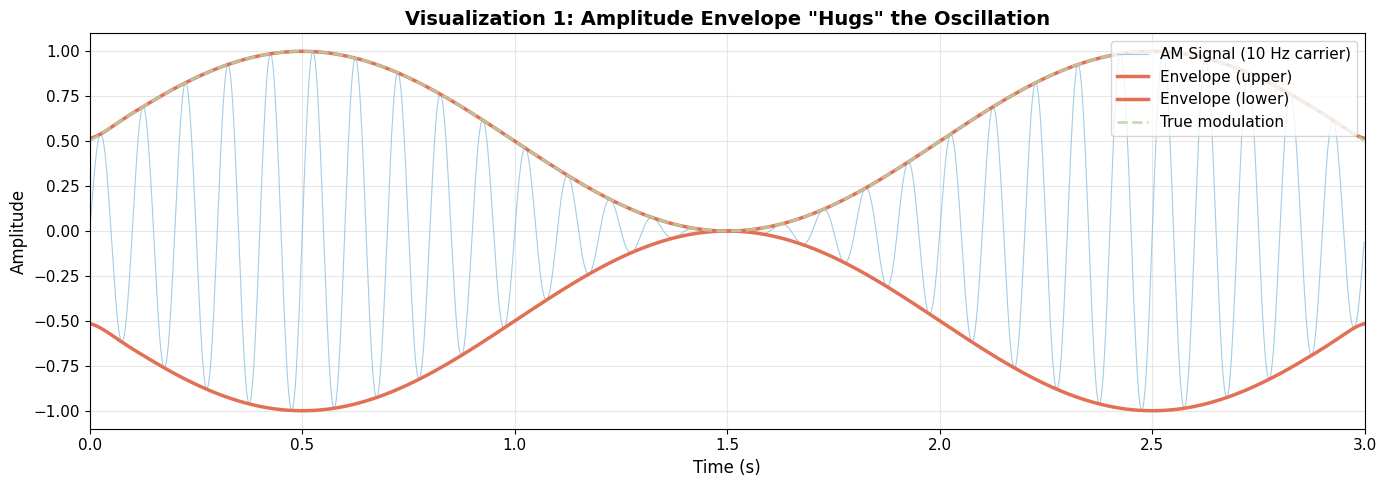

Carrier frequency: 10 Hz
Modulation frequency: 0.5 Hz
→ The envelope captures the slow amplitude changes!


In [2]:
# ============================================================================
# VISUALIZATION 1: Amplitude-Modulated Signal with Envelope
# ============================================================================

# Create an amplitude-modulated signal
fs = 500  # Sampling rate
duration = 3.0  # seconds
t = np.arange(0, duration, 1/fs)

# Carrier: 10 Hz oscillation
carrier_freq = 10  # Hz
carrier = np.sin(2 * np.pi * carrier_freq * t)

# Modulation: slow 0.5 Hz envelope variation
mod_freq = 0.5  # Hz
modulation = 0.5 + 0.5 * np.sin(2 * np.pi * mod_freq * t)  # Range [0, 1]

# AM signal
am_signal = modulation * carrier

# Extract envelope using Hilbert transform
analytic = hilbert(am_signal)
envelope = np.abs(analytic)

# Create figure
fig, ax = plt.subplots(figsize=(14, 5))

# Plot signal
ax.plot(t, am_signal, color=PRIMARY_BLUE, linewidth=0.8, alpha=0.7, label='AM Signal (10 Hz carrier)')

# Plot envelope (upper and lower)
ax.plot(t, envelope, color=PRIMARY_RED, linewidth=2.5, label='Envelope (upper)')
ax.plot(t, -envelope, color=PRIMARY_RED, linewidth=2.5, label='Envelope (lower)')

# Plot true modulation for comparison
ax.plot(t, modulation, color=PRIMARY_GREEN, linewidth=2, linestyle='--', 
        alpha=0.8, label='True modulation')

ax.set_xlabel('Time (s)', fontsize=12)
ax.set_ylabel('Amplitude', fontsize=12)
ax.set_title('Visualization 1: Amplitude Envelope "Hugs" the Oscillation', 
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right')
ax.set_xlim(0, 3)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Carrier frequency: {carrier_freq} Hz")
print(f"Modulation frequency: {mod_freq} Hz")
print(f"→ The envelope captures the slow amplitude changes!")

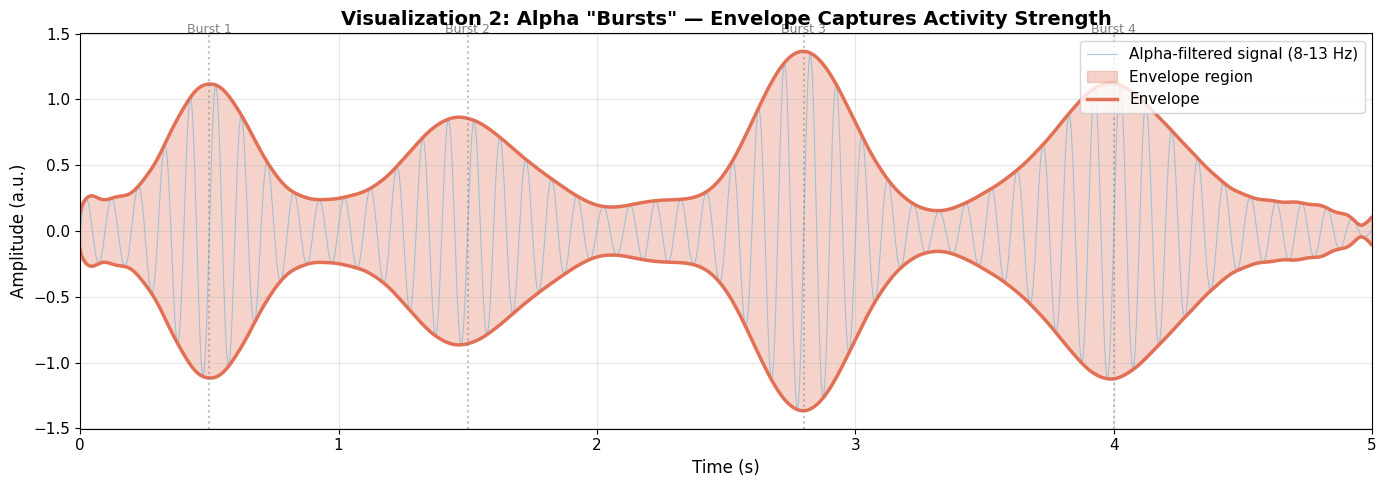

→ The envelope reveals WHEN alpha activity is strong (bursts) vs weak
→ This is crucial for understanding neural dynamics!


In [3]:
# ============================================================================
# VISUALIZATION 2: EEG-like Alpha Signal with Natural Envelope
# ============================================================================

# Generate realistic EEG-like signal with alpha activity
np.random.seed(42)
fs_eeg = 250
duration_eeg = 5.0
t_eeg = np.arange(0, duration_eeg, 1/fs_eeg)

# Create alpha bursts with varying amplitude
# Base alpha oscillation
alpha_freq = 10  # Hz

# Natural amplitude modulation (irregular bursts)
burst_mod = np.zeros(len(t_eeg))
# Add several bursts at random times
burst_times = [0.5, 1.5, 2.8, 4.0]  # seconds
burst_widths = [0.4, 0.6, 0.5, 0.7]  # seconds
burst_amps = [1.0, 0.7, 1.2, 0.9]

for bt, bw, ba in zip(burst_times, burst_widths, burst_amps):
    burst_mod += ba * np.exp(-((t_eeg - bt) ** 2) / (2 * (bw/3) ** 2))

# Add baseline and noise
burst_mod = 0.2 + burst_mod  # baseline

# Create alpha signal
alpha_signal = burst_mod * np.sin(2 * np.pi * alpha_freq * t_eeg)
alpha_signal += 0.15 * np.random.randn(len(t_eeg))  # Add noise

# Filter to alpha band and extract envelope
alpha_filtered = bandpass_filter(alpha_signal, 8, 13, fs_eeg)
alpha_analytic = hilbert(alpha_filtered)
alpha_envelope = np.abs(alpha_analytic)

# Create figure
fig, ax = plt.subplots(figsize=(14, 5))

# Plot filtered alpha signal
ax.plot(t_eeg, alpha_filtered, color=PRIMARY_BLUE, linewidth=0.8, 
        alpha=0.7, label='Alpha-filtered signal (8-13 Hz)')

# Plot envelope
ax.fill_between(t_eeg, -alpha_envelope, alpha_envelope, 
                color=PRIMARY_RED, alpha=0.3, label='Envelope region')
ax.plot(t_eeg, alpha_envelope, color=PRIMARY_RED, linewidth=2.5, label='Envelope')
ax.plot(t_eeg, -alpha_envelope, color=PRIMARY_RED, linewidth=2.5)

# Mark bursts
for i, bt in enumerate(burst_times):
    ax.axvline(x=bt, color='gray', linestyle=':', alpha=0.5)
    ax.annotate(f'Burst {i+1}', xy=(bt, alpha_envelope.max() * 1.1), 
                ha='center', fontsize=9, color='gray')

ax.set_xlabel('Time (s)', fontsize=12)
ax.set_ylabel('Amplitude (a.u.)', fontsize=12)
ax.set_title('Visualization 2: Alpha "Bursts" — Envelope Captures Activity Strength', 
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right')
ax.set_xlim(0, 5)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("→ The envelope reveals WHEN alpha activity is strong (bursts) vs weak")
print("→ This is crucial for understanding neural dynamics!")

---

## 3. Envelope vs Amplitude vs Power

These terms are often confused in the literature. Let's clarify:

| Term | Definition | Range | Units (if signal in µV) |
|------|------------|-------|-------------------------|
| **Signal amplitude** | $x(t)$ | $(-\infty, +\infty)$ | µV |
| **Instantaneous amplitude** | $|z(t)|$ | $[0, +\infty)$ | µV |
| **Envelope** | $|z(t)|$ | $[0, +\infty)$ | µV |
| **Instantaneous power** | $|z(t)|^2$ | $[0, +\infty)$ | µV² |

**Key distinctions**:
- **Envelope = Instantaneous amplitude** — these are synonymous!
- **Power = Envelope²** — squaring emphasizes large amplitudes
- **Band power** (from A03) is the *integral* of PSD over a frequency range

**When to use which?**
- **Envelope**: Standard for amplitude connectivity (CCorr)
- **Power**: Sometimes used, emphasizes peaks more
- In practice, results are often similar, but power is more sensitive to outliers

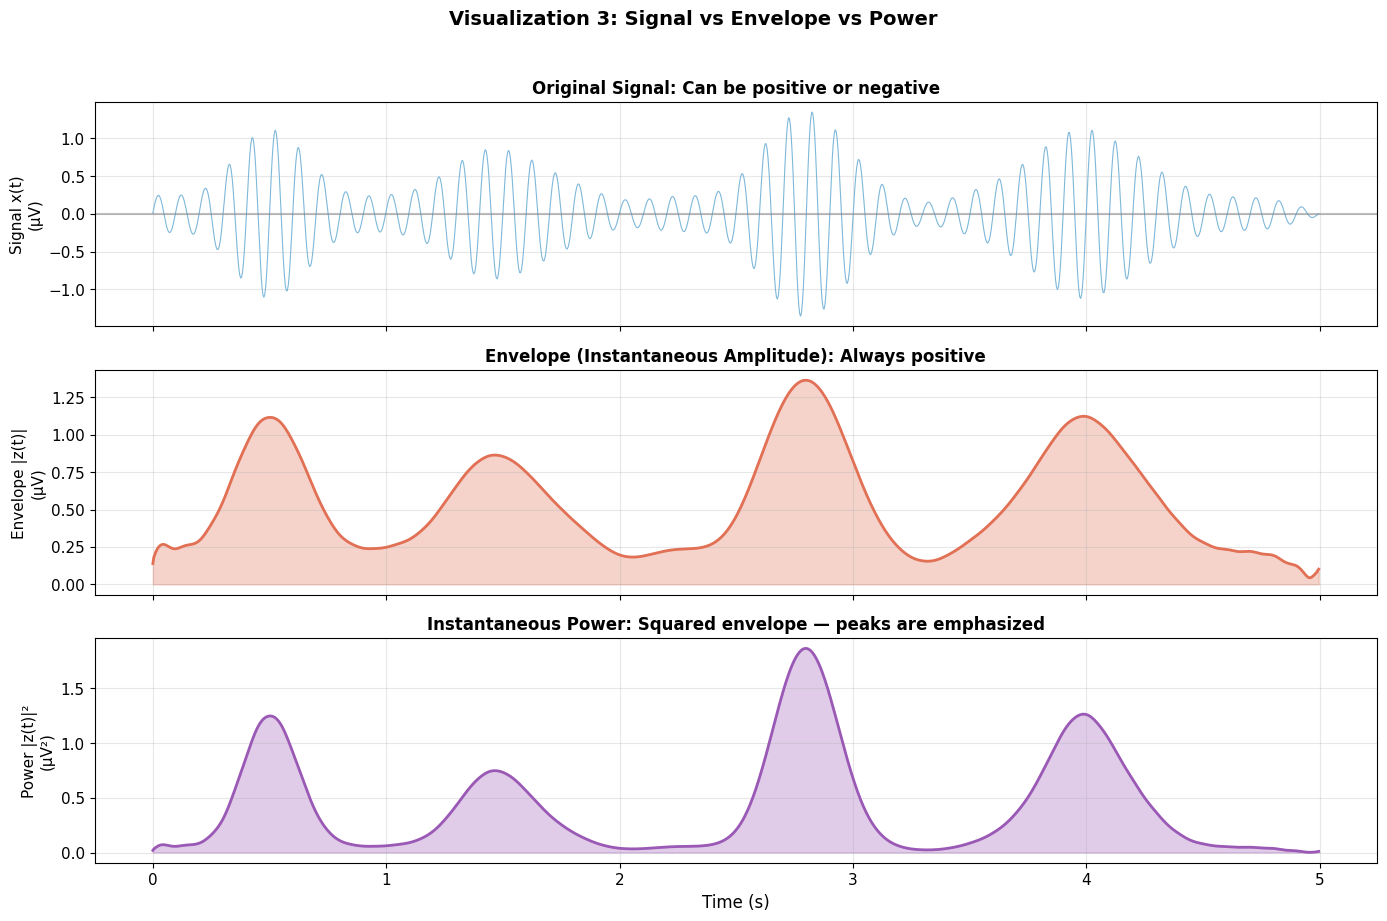

Correlation between envelope and power: 0.9739
→ They are highly correlated, but power emphasizes peaks more!


In [4]:
# ============================================================================
# VISUALIZATION 3: Signal vs Envelope vs Power
# ============================================================================

# Use the alpha signal from before
power = alpha_envelope ** 2

# Create figure with 3 subplots
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# Subplot 1: Original signal
axes[0].plot(t_eeg, alpha_filtered, color=PRIMARY_BLUE, linewidth=0.8)
axes[0].set_ylabel('Signal x(t)\n(µV)', fontsize=11)
axes[0].set_title('Original Signal: Can be positive or negative', 
                  fontsize=12, fontweight='bold')
axes[0].axhline(y=0, color='gray', linestyle='-', alpha=0.5)
axes[0].grid(True, alpha=0.3)

# Subplot 2: Envelope
axes[1].plot(t_eeg, alpha_envelope, color=PRIMARY_RED, linewidth=2)
axes[1].fill_between(t_eeg, 0, alpha_envelope, color=PRIMARY_RED, alpha=0.3)
axes[1].set_ylabel('Envelope |z(t)|\n(µV)', fontsize=11)
axes[1].set_title('Envelope (Instantaneous Amplitude): Always positive', 
                  fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

# Subplot 3: Power
axes[2].plot(t_eeg, power, color=ACCENT_PURPLE, linewidth=2)
axes[2].fill_between(t_eeg, 0, power, color=ACCENT_PURPLE, alpha=0.3)
axes[2].set_ylabel('Power |z(t)|²\n(µV²)', fontsize=11)
axes[2].set_xlabel('Time (s)', fontsize=12)
axes[2].set_title('Instantaneous Power: Squared envelope — peaks are emphasized', 
                  fontsize=12, fontweight='bold')
axes[2].grid(True, alpha=0.3)

plt.suptitle('Visualization 3: Signal vs Envelope vs Power', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Compute correlation between envelope and power
corr_env_pow = np.corrcoef(alpha_envelope, power)[0, 1]
print(f"Correlation between envelope and power: {corr_env_pow:.4f}")
print("→ They are highly correlated, but power emphasizes peaks more!")

---

## 4. Extracting the Envelope — Complete Pipeline

The standard workflow for envelope extraction:

1. **Filter** the signal to the frequency band of interest
2. Apply the **Hilbert transform** to get the analytic signal
3. Take the **magnitude** to get the envelope

**Why filtering first?**
- The envelope is only meaningful for **narrowband** signals
- A broadband signal has no single "envelope"
- The frequency band determines which oscillation we track

**Different bands = different envelopes = different dynamics!**

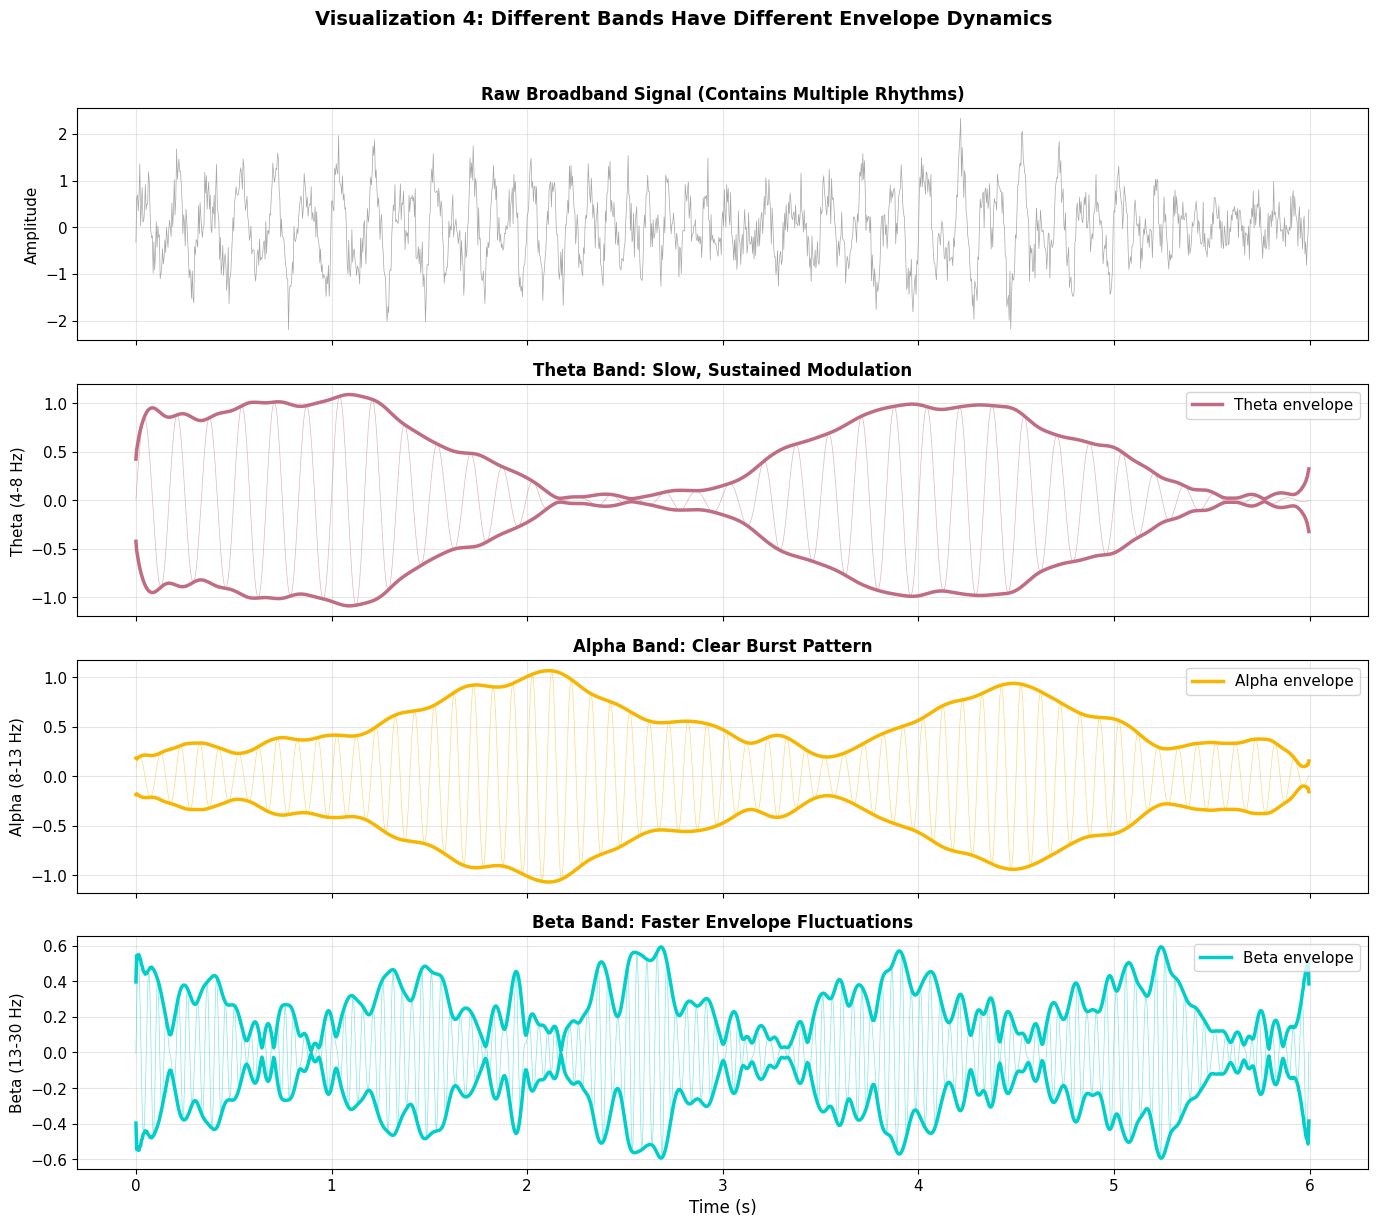

→ Each frequency band has its own characteristic envelope dynamics
→ The choice of band determines what neural activity we track!


In [5]:
# ============================================================================
# VISUALIZATION 4: Envelopes Across Different Frequency Bands
# ============================================================================

# Generate a broadband EEG-like signal with multiple components
np.random.seed(123)
fs_multi = 250
duration_multi = 6.0
t_multi = np.arange(0, duration_multi, 1/fs_multi)

# Create signal with theta, alpha, and beta components
# Each with different amplitude modulations
theta_mod = 0.5 + 0.5 * np.sin(2 * np.pi * 0.3 * t_multi)  # Slow modulation
alpha_mod = 0.3 + 0.7 * np.exp(-((t_multi - 2) ** 2) / 0.5) + 0.6 * np.exp(-((t_multi - 4.5) ** 2) / 0.3)
beta_mod = 0.4 + 0.4 * np.sin(2 * np.pi * 0.8 * t_multi + 1)  # Faster modulation

# Generate oscillations
theta = theta_mod * np.sin(2 * np.pi * 6 * t_multi)
alpha = alpha_mod * np.sin(2 * np.pi * 10 * t_multi)
beta = beta_mod * np.sin(2 * np.pi * 20 * t_multi)

# Combine with noise
broadband = theta + alpha + 0.5 * beta + 0.3 * np.random.randn(len(t_multi))

# Extract envelopes for each band
env_theta = extract_envelope(broadband, fs_multi, (4, 8))
env_alpha = extract_envelope(broadband, fs_multi, (8, 13))
env_beta = extract_envelope(broadband, fs_multi, (13, 30))

# Create figure
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

# Raw signal
axes[0].plot(t_multi, broadband, color='gray', linewidth=0.5, alpha=0.7)
axes[0].set_ylabel('Amplitude', fontsize=11)
axes[0].set_title('Raw Broadband Signal (Contains Multiple Rhythms)', 
                  fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Theta envelope
theta_filt = bandpass_filter(broadband, 4, 8, fs_multi)
axes[1].plot(t_multi, theta_filt, color=COLORS["theta"], linewidth=0.5, alpha=0.5)
axes[1].plot(t_multi, env_theta, color=COLORS["theta"], linewidth=2.5, label='Theta envelope')
axes[1].plot(t_multi, -env_theta, color=COLORS["theta"], linewidth=2.5)
axes[1].set_ylabel('Theta (4-8 Hz)', fontsize=11)
axes[1].set_title('Theta Band: Slow, Sustained Modulation', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

# Alpha envelope
alpha_filt = bandpass_filter(broadband, 8, 13, fs_multi)
axes[2].plot(t_multi, alpha_filt, color=COLORS["alpha"], linewidth=0.5, alpha=0.5)
axes[2].plot(t_multi, env_alpha, color=COLORS["alpha"], linewidth=2.5, label='Alpha envelope')
axes[2].plot(t_multi, -env_alpha, color=COLORS["alpha"], linewidth=2.5)
axes[2].set_ylabel('Alpha (8-13 Hz)', fontsize=11)
axes[2].set_title('Alpha Band: Clear Burst Pattern', fontsize=12, fontweight='bold')
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.3)

# Beta envelope
beta_filt = bandpass_filter(broadband, 13, 30, fs_multi)
axes[3].plot(t_multi, beta_filt, color=COLORS["beta"], linewidth=0.5, alpha=0.5)
axes[3].plot(t_multi, env_beta, color=COLORS["beta"], linewidth=2.5, label='Beta envelope')
axes[3].plot(t_multi, -env_beta, color=COLORS["beta"], linewidth=2.5)
axes[3].set_ylabel('Beta (13-30 Hz)', fontsize=11)
axes[3].set_xlabel('Time (s)', fontsize=12)
axes[3].set_title('Beta Band: Faster Envelope Fluctuations', fontsize=12, fontweight='bold')
axes[3].legend(loc='upper right')
axes[3].grid(True, alpha=0.3)

plt.suptitle('Visualization 4: Different Bands Have Different Envelope Dynamics', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("→ Each frequency band has its own characteristic envelope dynamics")
print("→ The choice of band determines what neural activity we track!")

---

## 5. Temporal Dynamics of the Envelope

A crucial insight: **envelopes fluctuate on slower timescales** than the oscillation itself.

- A 10 Hz alpha oscillation completes 10 cycles per second
- But its envelope might only change significantly over 0.5-2 seconds
- The envelope is essentially a **low-frequency signal**

This has important implications:
- Envelope dynamics reflect **neural modulation processes**
- They can reveal cognitive states, attention, arousal
- For connectivity, envelope correlation captures **slow co-fluctuation**

Let's verify this by looking at the frequency content of an envelope:

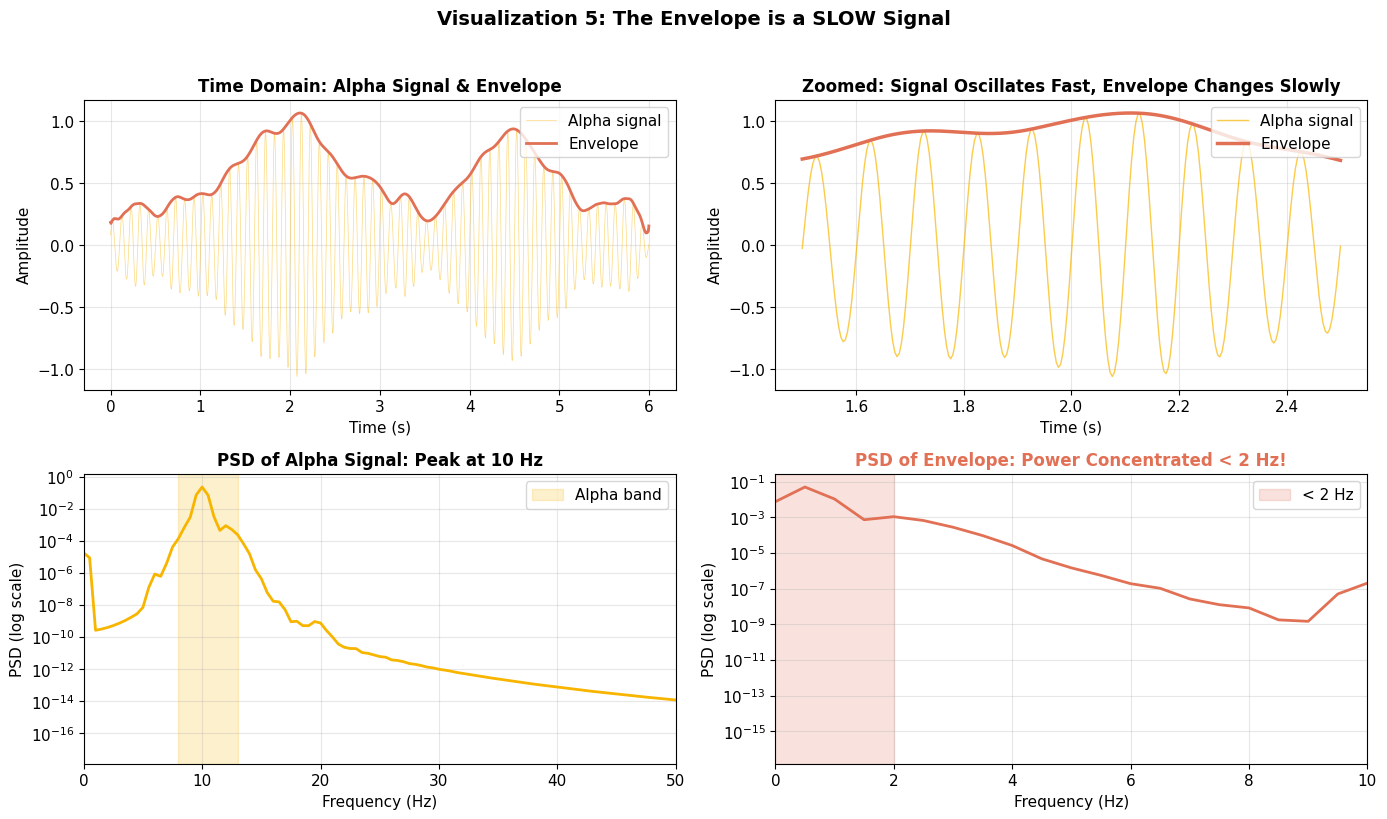

→ The alpha SIGNAL oscillates at ~10 Hz
→ The alpha ENVELOPE fluctuates at < 2 Hz
→ Envelope dynamics operate on a different (slower) timescale!


In [6]:
# ============================================================================
# VISUALIZATION 5: Envelope is a Slow Signal
# ============================================================================

# Use alpha envelope from previous example
freqs_env, psd_env = compute_envelope_psd(env_alpha, fs_multi)

# Also compute PSD of the filtered signal for comparison
from scipy.signal import welch
freqs_sig, psd_sig = welch(alpha_filt, fs=fs_multi, nperseg=int(fs_multi * 2))

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Top left: Alpha signal and envelope in time domain
axes[0, 0].plot(t_multi, alpha_filt, color=COLORS["alpha"], linewidth=0.5, 
                alpha=0.5, label='Alpha signal')
axes[0, 0].plot(t_multi, env_alpha, color=PRIMARY_RED, linewidth=2, label='Envelope')
axes[0, 0].set_xlabel('Time (s)', fontsize=11)
axes[0, 0].set_ylabel('Amplitude', fontsize=11)
axes[0, 0].set_title('Time Domain: Alpha Signal & Envelope', fontsize=12, fontweight='bold')
axes[0, 0].legend(loc='upper right')
axes[0, 0].grid(True, alpha=0.3)

# Top right: Zoomed view
zoom_start, zoom_end = 1.5, 2.5
zoom_mask = (t_multi >= zoom_start) & (t_multi <= zoom_end)
axes[0, 1].plot(t_multi[zoom_mask], alpha_filt[zoom_mask], color=COLORS["alpha"], 
                linewidth=1, alpha=0.7, label='Alpha signal')
axes[0, 1].plot(t_multi[zoom_mask], env_alpha[zoom_mask], color=PRIMARY_RED, 
                linewidth=2.5, label='Envelope')
axes[0, 1].set_xlabel('Time (s)', fontsize=11)
axes[0, 1].set_ylabel('Amplitude', fontsize=11)
axes[0, 1].set_title('Zoomed: Signal Oscillates Fast, Envelope Changes Slowly', 
                     fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='upper right')
axes[0, 1].grid(True, alpha=0.3)

# Bottom left: PSD of the alpha signal
axes[1, 0].semilogy(freqs_sig, psd_sig, color=COLORS["alpha"], linewidth=2)
axes[1, 0].axvspan(8, 13, color=COLORS["alpha"], alpha=0.2, label='Alpha band')
axes[1, 0].set_xlabel('Frequency (Hz)', fontsize=11)
axes[1, 0].set_ylabel('PSD (log scale)', fontsize=11)
axes[1, 0].set_title('PSD of Alpha Signal: Peak at 10 Hz', fontsize=12, fontweight='bold')
axes[1, 0].set_xlim(0, 50)
axes[1, 0].legend(loc='upper right')
axes[1, 0].grid(True, alpha=0.3)

# Bottom right: PSD of the envelope
axes[1, 1].semilogy(freqs_env, psd_env, color=PRIMARY_RED, linewidth=2)
axes[1, 1].axvspan(0, 2, color=PRIMARY_RED, alpha=0.2, label='< 2 Hz')
axes[1, 1].set_xlabel('Frequency (Hz)', fontsize=11)
axes[1, 1].set_ylabel('PSD (log scale)', fontsize=11)
axes[1, 1].set_title('PSD of Envelope: Power Concentrated < 2 Hz!', 
                     fontsize=12, fontweight='bold', color=PRIMARY_RED)
axes[1, 1].set_xlim(0, 10)
axes[1, 1].legend(loc='upper right')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('Visualization 5: The Envelope is a SLOW Signal', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("→ The alpha SIGNAL oscillates at ~10 Hz")
print("→ The alpha ENVELOPE fluctuates at < 2 Hz")
print("→ Envelope dynamics operate on a different (slower) timescale!")

---

## 6. Envelope Smoothing

Raw envelopes can be **noisy**, especially with:
- Short data segments
- Low signal-to-noise ratio (SNR)
- High-frequency noise leaking through

**Smoothing** reduces rapid fluctuations and reveals the underlying trend.

**Common methods**:
1. **Moving average**: Simple, but distorts edges
2. **Gaussian smoothing**: Better edge behavior
3. **Low-pass filtering**: Most principled approach

**Trade-off**: More smoothing = less temporal resolution

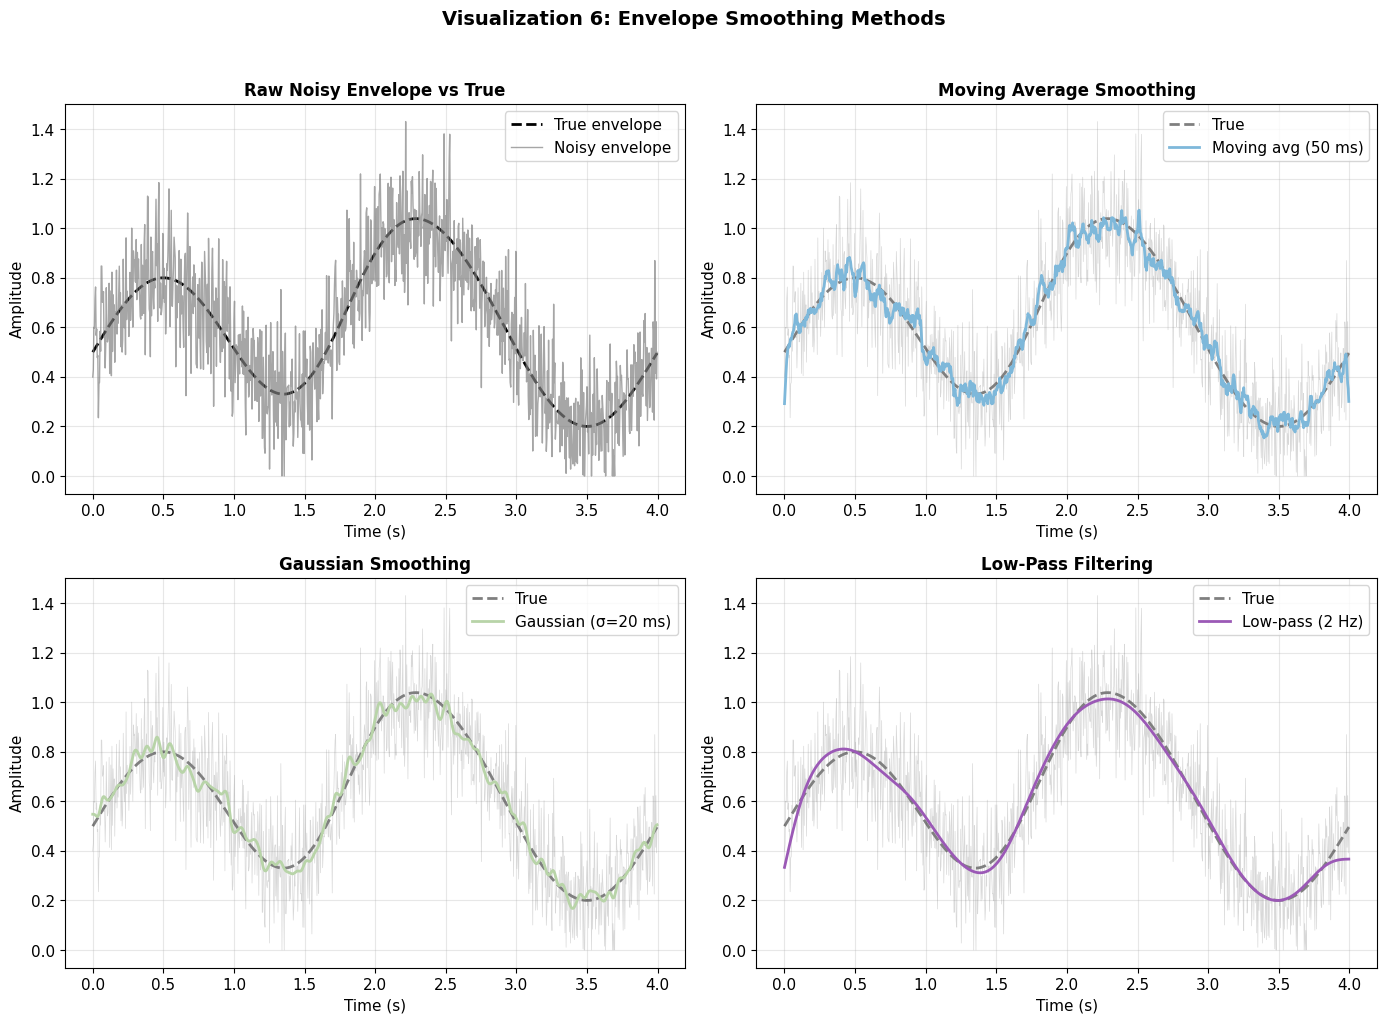

Mean Squared Error from true envelope:
  Raw:            0.0219
  Moving average: 0.0016
  Gaussian:       0.0009
  Low-pass:       0.0008

→ All smoothing methods improve the estimate!


In [7]:
# ============================================================================
# VISUALIZATION 6: Comparing Smoothing Methods
# ============================================================================

# Create a noisy envelope for demonstration
np.random.seed(456)
fs_smooth = 250
duration_smooth = 4.0
t_smooth = np.arange(0, duration_smooth, 1/fs_smooth)

# True underlying envelope (smooth)
true_envelope = 0.5 + 0.3 * np.sin(2 * np.pi * 0.5 * t_smooth)
true_envelope += 0.4 * np.exp(-((t_smooth - 2) ** 2) / 0.3)

# Add noise to create "raw" envelope
raw_envelope = true_envelope + 0.15 * np.random.randn(len(t_smooth))
raw_envelope = np.maximum(raw_envelope, 0)  # Envelope must be positive

# Apply smoothing methods
window_ms = 50  # 50 ms window
window_samples = int(window_ms * fs_smooth / 1000)

sigma_ms = 20  # 20 ms sigma
sigma_samples = sigma_ms * fs_smooth / 1000

smooth_ma = smooth_envelope_moving_average(raw_envelope, window_samples)
smooth_gauss = smooth_envelope_gaussian(raw_envelope, sigma_samples)
smooth_lp = smooth_envelope_lowpass(raw_envelope, fs_smooth, cutoff=2.0)

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top left: Raw vs True
axes[0, 0].plot(t_smooth, true_envelope, color='black', linewidth=2, 
                linestyle='--', label='True envelope')
axes[0, 0].plot(t_smooth, raw_envelope, color='gray', linewidth=1, 
                alpha=0.7, label='Noisy envelope')
axes[0, 0].set_xlabel('Time (s)', fontsize=11)
axes[0, 0].set_ylabel('Amplitude', fontsize=11)
axes[0, 0].set_title('Raw Noisy Envelope vs True', fontsize=12, fontweight='bold')
axes[0, 0].legend(loc='upper right')
axes[0, 0].grid(True, alpha=0.3)

# Top right: Moving average
axes[0, 1].plot(t_smooth, true_envelope, color='black', linewidth=2, 
                linestyle='--', label='True', alpha=0.5)
axes[0, 1].plot(t_smooth, raw_envelope, color='gray', linewidth=0.5, alpha=0.3)
axes[0, 1].plot(t_smooth, smooth_ma, color=PRIMARY_BLUE, linewidth=2, 
                label=f'Moving avg ({window_ms} ms)')
axes[0, 1].set_xlabel('Time (s)', fontsize=11)
axes[0, 1].set_ylabel('Amplitude', fontsize=11)
axes[0, 1].set_title('Moving Average Smoothing', fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='upper right')
axes[0, 1].grid(True, alpha=0.3)

# Bottom left: Gaussian
axes[1, 0].plot(t_smooth, true_envelope, color='black', linewidth=2, 
                linestyle='--', label='True', alpha=0.5)
axes[1, 0].plot(t_smooth, raw_envelope, color='gray', linewidth=0.5, alpha=0.3)
axes[1, 0].plot(t_smooth, smooth_gauss, color=PRIMARY_GREEN, linewidth=2, 
                label=f'Gaussian (σ={sigma_ms} ms)')
axes[1, 0].set_xlabel('Time (s)', fontsize=11)
axes[1, 0].set_ylabel('Amplitude', fontsize=11)
axes[1, 0].set_title('Gaussian Smoothing', fontsize=12, fontweight='bold')
axes[1, 0].legend(loc='upper right')
axes[1, 0].grid(True, alpha=0.3)

# Bottom right: Low-pass
axes[1, 1].plot(t_smooth, true_envelope, color='black', linewidth=2, 
                linestyle='--', label='True', alpha=0.5)
axes[1, 1].plot(t_smooth, raw_envelope, color='gray', linewidth=0.5, alpha=0.3)
axes[1, 1].plot(t_smooth, smooth_lp, color=ACCENT_PURPLE, linewidth=2, 
                label='Low-pass (2 Hz)')
axes[1, 1].set_xlabel('Time (s)', fontsize=11)
axes[1, 1].set_ylabel('Amplitude', fontsize=11)
axes[1, 1].set_title('Low-Pass Filtering', fontsize=12, fontweight='bold')
axes[1, 1].legend(loc='upper right')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('Visualization 6: Envelope Smoothing Methods', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Compare errors
mse_raw = np.mean((raw_envelope - true_envelope) ** 2)
mse_ma = np.mean((smooth_ma - true_envelope) ** 2)
mse_gauss = np.mean((smooth_gauss - true_envelope) ** 2)
mse_lp = np.mean((smooth_lp - true_envelope) ** 2)

print("Mean Squared Error from true envelope:")
print(f"  Raw:            {mse_raw:.4f}")
print(f"  Moving average: {mse_ma:.4f}")
print(f"  Gaussian:       {mse_gauss:.4f}")
print(f"  Low-pass:       {mse_lp:.4f}")
print("\n→ All smoothing methods improve the estimate!")

---

<a id="summary"></a>
## 7. 📝 Summary

### Key Takeaways

1. **Amplitude Envelope Definition**
   - The envelope traces the slow-varying amplitude modulation of an oscillation
   - Extracted via Hilbert transform: `envelope = |analytic_signal|`
   - Represents the "strength" of neural oscillations at each moment

2. **Complete Extraction Pipeline**
   - Bandpass filter → Hilbert transform → Magnitude
   - The filter must be applied first to isolate the frequency band of interest
   - Edge effects from filtering can corrupt the envelope near the signal boundaries

3. **Envelope is a Slow Signal**
   - Envelope frequencies are much lower than the carrier oscillation
   - Typically < 2–3 Hz for most cognitive processes
   - The envelope's own power spectrum reveals its modulation timescales

4. **Smoothing Methods**
   - Moving average: simple, may introduce discontinuities
   - Gaussian: smooth output, sigma controls the trade-off
   - Low-pass filter: principled frequency cutoff
   - Trade-off: noise reduction vs temporal smearing

### Functions Implemented

| Function | Purpose |
|----------|---------|
| `extract_envelope(signal, fs, band)` | Filter + Hilbert + magnitude |
| `compute_envelope_psd(envelope, fs)` | Power spectrum of envelope |
| `smooth_envelope_moving_average()` | Simple sliding window |
| `smooth_envelope_gaussian()` | Gaussian filter smoothing |
| `smooth_envelope_lowpass()` | Low-pass Butterworth filter |


---

<a id="discussion-questions"></a>
## 8. 💬 Discussion Questions

1. **Why filter first?** The envelope extraction pipeline requires bandpass filtering *before* the Hilbert transform. What would go wrong if you applied the Hilbert transform to the raw (broadband) EEG signal?

2. **Smoothing trade-offs**: You need to track alpha power fluctuations that occur on a 500 ms timescale. How would you choose the smoothing parameters? Would you use Gaussian, moving average, or low-pass filtering?

3. **Envelope vs Power**: Some papers use the square of the envelope (instantaneous power) rather than the envelope itself. When does this distinction matter? What are the statistical properties of power vs amplitude?

4. **Temporal resolution**: How does the carrier frequency of a signal constrain the temporal resolution of its envelope? Can you track 10 Hz envelope fluctuations in an alpha (10 Hz) signal?

5. **EEG application**: In resting-state EEG, the alpha envelope often shows intermittent "bursts" of activity. What physiological processes might produce this burst-like pattern?


---

<a id="external-resources"></a>
## 9. 🔗 External Resources

### 📚 Scientific References

- **Gabor, D. (1946)** - *Theory of communication* — Original paper on analytic signals and instantaneous amplitude/phase
- **Hilbert, D. (1912)** - *Grundzüge einer allgemeinen Theorie der linearen Integralgleichungen* — Mathematical foundation of the Hilbert transform
- **Cohen, M.X. (2014)** - *Analyzing Neural Time Series Data* (MIT Press) — Chapter 11: The Hilbert transform and the analytic signal

### 🎧 NotebookLM Resources

*(NotebookLM links will be added once this notebook is finalized)*

### 🔗 Next Steps

Continue to **[B03b: Envelope Correlation and Connectivity](B03b_envelope_correlation.ipynb)** to learn how to measure amplitude coupling between signals as a connectivity metric.
